In [ ]:
import numpy as np
from pyod.utils.data import generate_data
import matplotlib.pyplot as plt

X_train, X_test, y_train, y_test = generate_data(
    n_train=400,
    n_test=100,
    n_features=2,
    contamination=0.1,
    random_state=42,
)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)


(400, 2)
(100, 2)
(400,)
(100,)


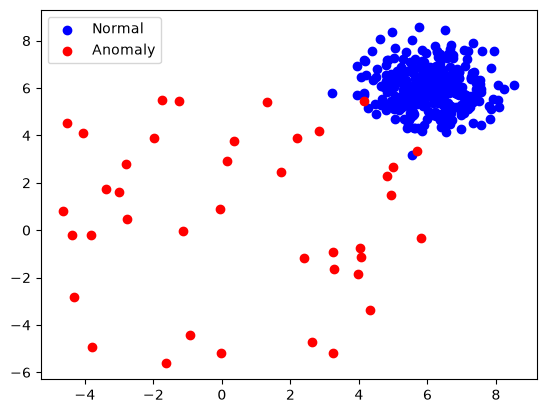

In [11]:
x = X_train[:, 0]
y = X_train[:, 1]

normal_mask = (y_train == 0)
X_train[normal_mask]
normal_data = X_train[normal_mask]

plt.scatter(
    normal_data[:, 0],
    normal_data[:, 1],
    color="blue",
    label = "Normal"
)

anomaly_mask = (y_train == 1)
anomaly_data = X_train[anomaly_mask]

plt.scatter(
    anomaly_data[:, 0],
    anomaly_data[:, 1],
    color = "red",
    label = "Anomaly"
)
plt.legend()
plt.show()

Ex. 2
Choose a model from pyod (ex: KNN), leave all the parameters default (ex-
cept the contamination, which will match the contamination used for dataset
generation) and fit it with the training data. Get the predictions of the model
for both the training and the testing data.
Use the confusion matrix function from sklearn.metrics to find the
number of TN, TP, FN and FP and compute the balanced accuracy.
Use the roc curve() function from sklearn.metrics to compute the ROC
curve and then plot it with plot() function.
Change the contamination rate used by the model and see how the reported
metrics change.

(100,)


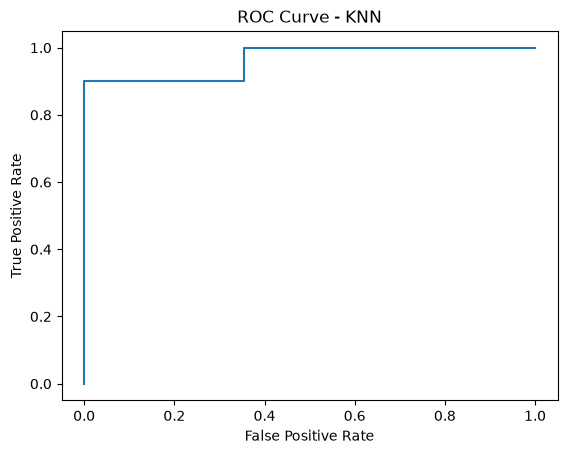

In [12]:
from pyod.models.knn import KNN
from sklearn.metrics import roc_curve
from sklearn.metrics import confusion_matrix

model = KNN(contamination=0.1)
model.fit(X_train)

train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)

cm = confusion_matrix(y_test, test_predictions)

cm.ravel()

tn, fp, fn, tp = cm[0][0], cm[0][1], cm[1][0], cm[1][1]

tpr = tp / (tp + fn)
tnr = tn / (tn + fp)
balanced_accuracy = (tpr + tnr) / 2

test_scores = model.decision_function(X_test)

print(test_scores.shape)

fpr, tpr, thresholds = roc_curve(y_test, test_scores)

plt.plot(fpr, tpr)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - KNN")
plt.show()

Ex. 3
Generate a unidimensional dataset with 10 % contamination rate, 1000 train-
ing samples and no testing samples using generate data(). Try to detect the
anomalies in the dataset by using the Z-scores. In order to do that you should
compute the Z-score threshold that would classify the given percent (contami-
nation rate) of data as anomalies (use np.quantile() function). Compute the
balanced accuracy of the designed method.

In [13]:
from sklearn.metrics import confusion_matrix

X_train, X_test, y_train, y_test = generate_data(
    n_train=1000,
    n_test=0,
    n_features=1,
    contamination=0.1,
    random_state=42,
)

mean = np.mean(X_train)
std = np.std(X_train)

z_score =  (X_train - mean) / std

abs_z_score = np.abs(z_score) 

threshold  = np.quantile(abs_z_score, 0.9)

predictions = (abs_z_score > threshold).astype(int)

cm = confusion_matrix(y_train, predictions)

print(cm)

tn, fp, fn, tp = cm[0][0], cm[0][1], cm[1][0], cm[1][1]

tpr = tp / (tp + fn)
tnr = tn / (tn + fp)
balanced_accuracy = (tpr + tnr) / 2

print(balanced_accuracy)


[[871  29]
 [ 29  71]]
0.8388888888888888


Ex. 4
Same as Ex. 3 but for a multidimensional dataset. Choose your own mean
vector μ and covariance matrix Σ and build your dataset by hand starting with
the samples generated from a multivariate standard normal distribution, x ∼
N (0, I). Using the Cholesky decomposition of the covariance matrix Σ = LLT
draw your samples y like this: y = Lx + μ and then compute the Z-scores. All
other tasks as in Ex. 3.

In [23]:
import numpy.linalg as npl

mu = np.array([5, 10])

sigma = np.array([
    [9, 6],
    [6, 20]
    ])

L = npl.cholesky(sigma)

X = np.random.standard_normal(size=(1000, 2))

Y = X @ L.T + mu

print(Y)

empirical_cov =  np.cov(Y, rowvar = False)

[[ 6.83829586 13.56532373]
 [ 7.28472107 10.67006275]
 [ 7.47491325  1.30356019]
 ...
 [ 1.86240737  3.26805073]
 [ 7.34469113 12.84589326]
 [ 1.31870757  6.11423593]]
